# Automatic differentiation with PyTorch

`DarkEmulator2(autodiff="torch")` returns `P(k)` and `C_ell` as differentiable PyTorch tensors.

- exact derivatives, no finite-difference step
- derivatives for all parameters in one call, also on GPUs
- usable in Fisher matrices, optimizers and HMC/NUTS ([Pyro](https://docs.pyro.ai/))

## Setup

In [1]:
# %pip install pyro-ppl dark_emulator2

In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import pyro
import pyro.distributions as dist
from pyro.infer import MCMC, NUTS
from dark_emulator2 import DarkEmulator2

device = "cuda" if torch.cuda.is_available() else "cpu"
de = DarkEmulator2()
emu = DarkEmulator2(autodiff="torch", device=device, dtype=torch.float64)

fiducial = {
    "Omega_m": 0.3156,
    "h0": 0.6723,
    "omega_b": 0.02225,
    "sigma8": 0.831,
    "ns": 0.9645,
    "Mnu": 0.06,
    "Omega_k": 0.0,
    "w0": -1.0,
    "wa": 0.0,
}

## Device and precision

- `device`: `"cpu"` (default), `"cuda"`, `"cuda:N"`
- `dtype`: `torch.get_default_dtype()` by default; float64 is recommended for HMC ([torch.set_default_dtype](https://docs.pytorch.org/docs/stable/generated/torch.set_default_dtype.html))
- `get_pk`, `get_lin_pk`, `get_cl_limber`, `get_lin_cl_limber`, `get_sigma8` and `get_lnAs` return tensors; other methods return numpy arrays

In [3]:
k, pk = emu.get_pk(fiducial)
print(pk.device, pk.dtype, tuple(pk.shape))

cuda:0 torch.float64 (301,)


## Same outputs as `DarkEmulator2`

In [4]:
zred = [0.0, 0.5, 1.0]
k, pk = emu.get_pk(fiducial, zred=zred, pk_type="total")
_, pk_ref = de.get_pk(fiducial, zred=zred, pk_type="total")
print("P(k)  max relative difference:", np.max(np.abs(pk.cpu().numpy() / pk_ref - 1)))

ell_ref, cl = emu.get_cl_limber(fiducial)
_, cl_ref = de.get_cl_limber(fiducial)
print("C_ell max relative difference:", np.max(np.abs(cl.cpu().numpy() / cl_ref - 1)))

P(k)  max relative difference: 1.2742985526781325e-06
C_ell max relative difference: 7.831003847602602e-07


## Exact derivatives

Finite differences of `DarkEmulator2` depend on the step; automatic differentiation does not.

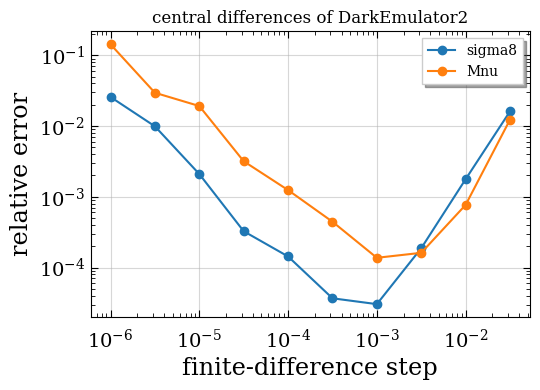

In [5]:
z_cl = np.linspace(0.0, 1.0, 61)
k_cl = np.logspace(-3, 2, 301)
ell = np.logspace(1, 4, 30)
names = ["Omega_m", "sigma8", "h0", "ns", "omega_b", "Mnu", "w0", "wa", "Omega_k"]


def ln_cl(theta):
    return torch.log(emu.get_cl_limber({**fiducial, **dict(zip(names, theta))}, zlist=z_cl, klist=k_cl, llist=ell)[1])


theta0 = torch.tensor([fiducial[n] for n in names], dtype=torch.float64, device=device)
jac = torch.func.jacfwd(ln_cl)(theta0).cpu().numpy()


def ln_cl_de2(p):
    return np.log(de.get_cl_limber(p, zlist=z_cl, klist=k_cl, llist=ell)[1])


steps = np.logspace(-1.5, -6, 10)
fig, ax = plt.subplots(figsize=(5.5, 4))
for name in ["sigma8", "Mnu"]:
    i = names.index(name)
    errors = []
    for h in steps:
        fd = (ln_cl_de2({**fiducial, name: fiducial[name] + h}) - ln_cl_de2({**fiducial, name: fiducial[name] - h})) / (2 * h)
        errors.append(np.max(np.abs(fd - jac[:, i])) / np.max(np.abs(jac[:, i])))
    ax.loglog(steps, errors, "o-", label=name)
ax.set_xlabel("finite-difference step")
ax.set_ylabel("relative error")
ax.set_title("central differences of DarkEmulator2")
ax.legend()
plt.tight_layout()
plt.show()

## Fast gradients

Derivatives for 9 parameters: one call vs. 18 evaluations with central differences.

In [6]:
t0 = time.perf_counter()
torch.func.jacfwd(ln_cl)(theta0).cpu()
t_ad = time.perf_counter() - t0

t0 = time.perf_counter()
ln_cl_de2(fiducial)
t_de2 = time.perf_counter() - t0

print(f"derivatives of C_ell with respect to {len(names)} parameters:")
print(f"  automatic differentiation:              {t_ad:.3g} s")
print(f"  central differences with DarkEmulator2: {2 * len(names) * t_de2:.3g} s ({2 * len(names)} evaluations)")

derivatives of C_ell with respect to 9 parameters:
  automatic differentiation:              0.0422 s
  central differences with DarkEmulator2: 2.78 s (18 evaluations)


## Fisher matrix and NUTS

- Toy likelihood (not a survey analysis): fake `C_ell` at `Omega_m = 0.45`, `sigma8 = 0.62`, 5% error on `ln C_ell`
- Fisher matrix from one Jacobian; NUTS uses the gradients
- The prior box is inside the DE2 support, since NUTS needs a smooth target

In [7]:
z_data = np.linspace(0.0, 2.0, 101)
k_data = np.logspace(-3, 1, 201)
ell_data = np.logspace(1, 4, 40)
sigma_logcl = 0.05
truth = np.array([0.45, 0.62])
omega_m_prior, sigma8_prior = (0.40, 0.50), (0.56, 0.68)

print("prior box corners in support:",
      [de.is_in_support({**fiducial, "Omega_m": om, "sigma8": s8}) for om in omega_m_prior for s8 in sigma8_prior])


def model_ln_cl(omega_m, sigma8):
    return torch.log(emu.get_cl_limber({**fiducial, "Omega_m": omega_m, "sigma8": sigma8}, zlist=z_data, klist=k_data, llist=ell_data)[1])


log_cl_data = model_ln_cl(*truth)
J = torch.func.jacfwd(lambda t: model_ln_cl(t[0], t[1]))(torch.tensor(truth, device=device)).cpu().numpy()
fisher_cov = np.linalg.inv(J.T @ J / sigma_logcl**2)
print("Fisher 1-sigma errors (Omega_m, sigma8):", np.sqrt(np.diag(fisher_cov)))


def uniform(lo, hi):
    return dist.Uniform(torch.tensor(lo, dtype=torch.float64, device=device), torch.tensor(hi, dtype=torch.float64, device=device))


def model():
    omega_m = pyro.sample("Omega_m", uniform(*omega_m_prior))
    sigma8 = pyro.sample("sigma8", uniform(*sigma8_prior))
    pyro.sample("obs", dist.Normal(model_ln_cl(omega_m, sigma8), sigma_logcl).to_event(1), obs=log_cl_data)

prior box corners in support: [True, True, True, True]
Fisher 1-sigma errors (Omega_m, sigma8): [0.00652215 0.00421383]


In [8]:
n_warmup, n_samples = 500, 2000
pyro.set_rng_seed(0)
t0 = time.perf_counter()
mcmc = MCMC(NUTS(model), num_samples=n_samples, warmup_steps=n_warmup, disable_progbar=True)
mcmc.run()
print(f"NUTS: {n_warmup + n_samples} iterations in {time.perf_counter() - t0:.0f} s")
mcmc.summary()
samples = {name: value.cpu().numpy() for name, value in mcmc.get_samples().items()}

NUTS: 2500 iterations in 253 s

                mean       std    median      5.0%     95.0%     n_eff     r_hat
   Omega_m      0.45      0.01      0.45      0.44      0.46    470.26      1.00
    sigma8      0.62      0.00      0.62      0.61      0.63    495.57      1.00

Number of divergences: 0


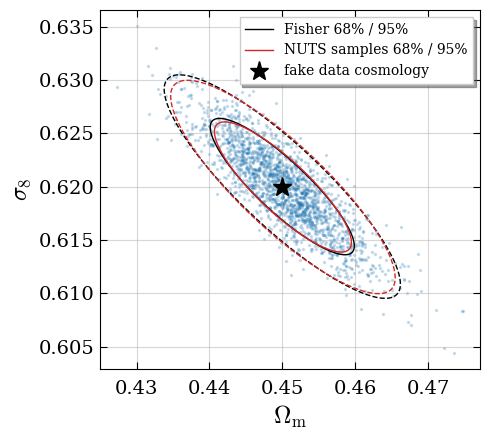

In [9]:
t = np.linspace(0, 2 * np.pi, 200)
circle = np.array([np.cos(t), np.sin(t)])
xy = np.array([samples["Omega_m"], samples["sigma8"]])
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(*xy, s=2, alpha=0.2, color="C0")
for cov, center, color, label in [(fisher_cov, truth, "k", "Fisher"), (np.cov(xy), xy.mean(axis=1), "C3", "NUTS samples")]:
    vals, vecs = np.linalg.eigh(cov)
    for dchi2, ls in [(2.30, "-"), (6.18, "--")]:
        ax.plot(*(center[:, None] + vecs @ (np.sqrt(dchi2 * vals)[:, None] * circle)), color=color, ls=ls, lw=1)
    ax.plot([], [], color=color, lw=1, label=f"{label} 68% / 95%")
ax.plot(*truth, "*", color="k", ms=14, label="fake data cosmology")
ax.set_xlabel(r"$\Omega_{\rm m}$")
ax.set_ylabel(r"$\sigma_8$")
ax.legend()
plt.tight_layout()
plt.show()

## Many cosmologies in one call

Parameters can be arrays.

In [10]:
n = 500
rng = np.random.default_rng(0)
batch = {**fiducial, "Omega_m": torch.tensor(rng.uniform(0.25, 0.35, n), device=device), "sigma8": torch.tensor(rng.uniform(0.75, 0.9, n), device=device)}
emu.get_pk(fiducial, zred=0.5)

t0 = time.perf_counter()
k, pk_batch = emu.get_pk(batch, zred=0.5)
pk_batch = pk_batch.cpu()
t_batch = time.perf_counter() - t0

t0 = time.perf_counter()
for om, s8 in zip(batch["Omega_m"][:50].tolist(), batch["sigma8"][:50].tolist()):
    de.get_pk({**fiducial, "Omega_m": om, "sigma8": s8}, zred=0.5)
t_loop = (time.perf_counter() - t0) / 50 * n

print(f"P(k) of {n} cosmologies {tuple(pk_batch.shape)}: one call {t_batch:.3g} s | DarkEmulator2 loop about {t_loop:.3g} s")

P(k) of 500 cosmologies (500, 301): one call 0.00321 s | DarkEmulator2 loop about 3.6 s


## Notes

- Grids (`zred`, `klist`, `zlist`, `llist`, `src_dist`) must be fixed numpy arrays.
- Outputs differ from `DarkEmulator2` at the 1e-6 level (single-precision networks).
- Derivatives of `C_ell` are exact between the switches of the shot-noise cutoff.
- For production analyses, pass `P(k,z)` to the downstream likelihood when possible.